In [13]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

In [14]:
data_path = Path("../data/processed/flowcast_analysis_ready.parquet")
df = pd.read_parquet(data_path)

df["timestamp"] = pd.to_datetime(df["timestamp"])
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (176701, 43)


,timestamp,road_name,latitude,longitude,weather_station_id,date_x,time_x,traffic_volume,vehicle_count,vehicle_type_dist,...,speed_lag_1,volume_lag_2,speed_lag_2,volume_lag_48,speed_lag_48,volume_rolling_mean_4,volume_rolling_std_4,volume_rolling_mean_8,volume_rolling_std_8,vcr
2,2025-01-01 00:00:00,Airport Feeder,28.626508,77.212314,WS-SOUTH,2025-01-01,00:00,115.0,115,"{""2W"": 0.4, ""Car"": 0.35, ""LCV"": 0.16, ""HCV"": 0...",...,53.5,115.0,53.5,115.0,53.5,115.0,0.000000,115.0,0.000000,0.059156
48,2025-01-01 00:30:00,Airport Feeder,28.626508,77.212314,WS-SOUTH,2025-01-01,00:30,110.0,110,"{""2W"": 0.43, ""Car"": 0.35, ""LCV"": 0.13, ""HCV"": ...",...,53.5,115.0,53.5,115.0,53.5,115.0,0.000000,115.0,0.000000,0.056584
53,2025-01-01 01:00:00,Airport Feeder,28.626508,77.212314,WS-SOUTH,2025-01-01,01:00,114.0,114,"{""2W"": 0.42, ""Car"": 0.36, ""LCV"": 0.11, ""HCV"": ...",...,55.0,115.0,53.5,115.0,53.5,112.5,3.535534,112.5,3.535534,0.058642
86,2025-01-01 01:30:00,Airport Feeder,28.626508,77.212314,WS-SOUTH,2025-01-01,01:30,123.0,123,"{""2W"": 0.42, ""Car"": 0.4, ""LCV"": 0.09, ""HCV"": 0.1}",...,50.3,110.0,55.0,115.0,53.5,113.0,2.645751,113.0,2.645751,0.063272
101,2025-01-01 02:00:00,Airport Feeder,28.626508,77.212314,WS-SOUTH,2025-01-01,02:00,122.0,122,"{""2W"": 0.41, ""Car"": 0.33, ""LCV"": 0.13, ""HCV"": ...",...,54.0,114.0,50.3,115.0,53.5,115.5,5.446712,115.5,5.446712,0.062757


In [15]:
print("--- Data Summary ---")
print(df.info())
print("\n--- Numerical Feature Statistics ---")
df.describe().T[
    ["mean", "std", "min", "50%", "max"]
]  # Median (50%) and summary

--- Data Summary ---
<class 'pandas.DataFrame'>
Index: 176701 entries, 2 to 176682
Data columns (total 43 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   timestamp              176701 non-null  datetime64[us]
 1   road_name              176701 non-null  str           
 2   latitude               176701 non-null  float64       
 3   longitude              176701 non-null  float64       
 4   weather_station_id     176701 non-null  str           
 5   date_x                 176701 non-null  datetime64[us]
 6   time_x                 176701 non-null  str           
 7   traffic_volume         176701 non-null  float64       
 8   vehicle_count          176701 non-null  int64         
 9   vehicle_type_dist      176701 non-null  str           
 10  avg_speed              176701 non-null  float64       
 11  occupancy              176701 non-null  float64       
 12  congestion_level       176701 non-null 

,mean,std,min,50%,max
timestamp,2025-03-17 11:31:03.381644,NaN,2025-01-01 00:00:00,2025-03-17 11:00:00,2025-05-31 23:30:00
latitude,28.628368,0.033805,28.564352,28.626508,28.682634
longitude,77.198543,0.050548,77.106648,77.196308,77.312287
date_x,2025-03-16 23:46:14.632854,NaN,2025-01-01 00:00:00,2025-03-17 00:00:00,2025-05-31 00:00:00
traffic_volume,430.853722,283.488557,0.0,362.0,2090.0
vehicle_count,431.445221,283.555483,41.0,362.0,2090.0
avg_speed,42.104696,11.3761,6.7,44.9,64.8
occupancy,31.059269,19.377156,3.0,27.0,100.0
travel_time,3.565617,2.52868,0.8,3.12,29.91
accident_count,0.009434,0.097544,0.0,0.0,2.0


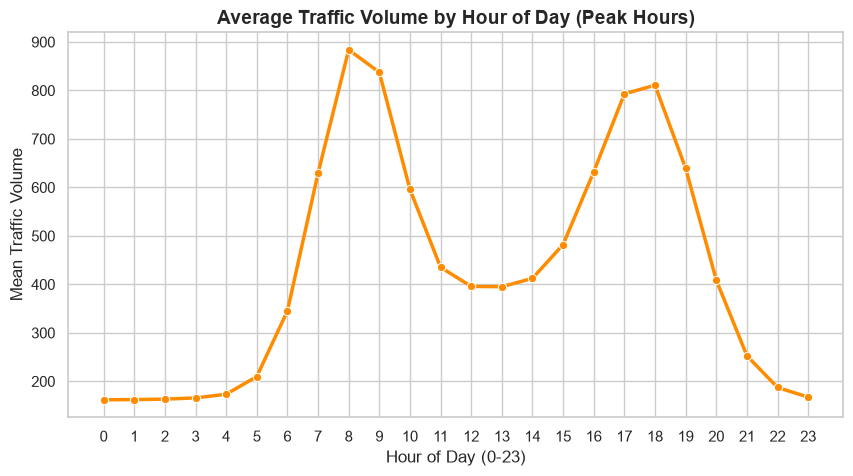

In [16]:
df["hour"] = df["timestamp"].dt.hour
hourly_traffic = df.groupby("hour")["traffic_volume"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=hourly_traffic,
    x="hour",
    y="traffic_volume",
    marker="o",
    color="darkorange",
    linewidth=2.5,
)
plt.title(
    "Average Traffic Volume by Hour of Day (Peak Hours)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Mean Traffic Volume", fontsize=12)
plt.xticks(range(0, 24))
plt.show()

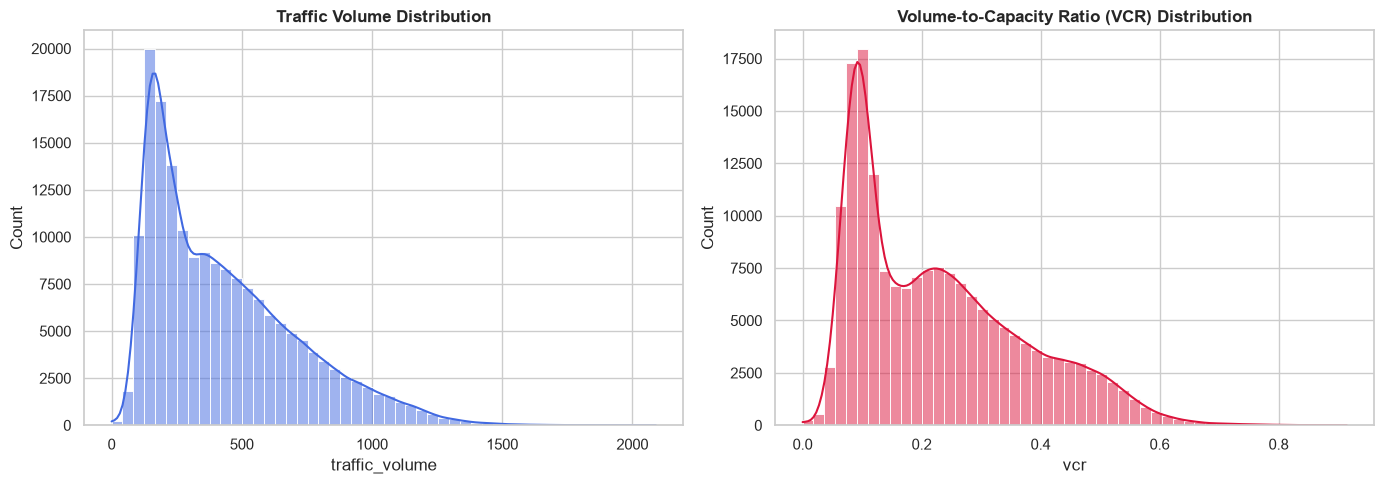

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Traffic Volume Distribution
sns.histplot(
    df["traffic_volume"], kde=True, color="royalblue", ax=axes[0], bins=50
)
axes[0].set_title("Traffic Volume Distribution", fontsize=12, fontweight="bold")

# Volume-to-Capacity Ratio (VCR) Distribution
if "vcr" in df.columns:
  sns.histplot(df["vcr"], kde=True, color="crimson", ax=axes[1], bins=50)
  axes[1].set_title(
      "Volume-to-Capacity Ratio (VCR) Distribution", fontsize=12, fontweight="bold"
  )

plt.tight_layout()
plt.show()

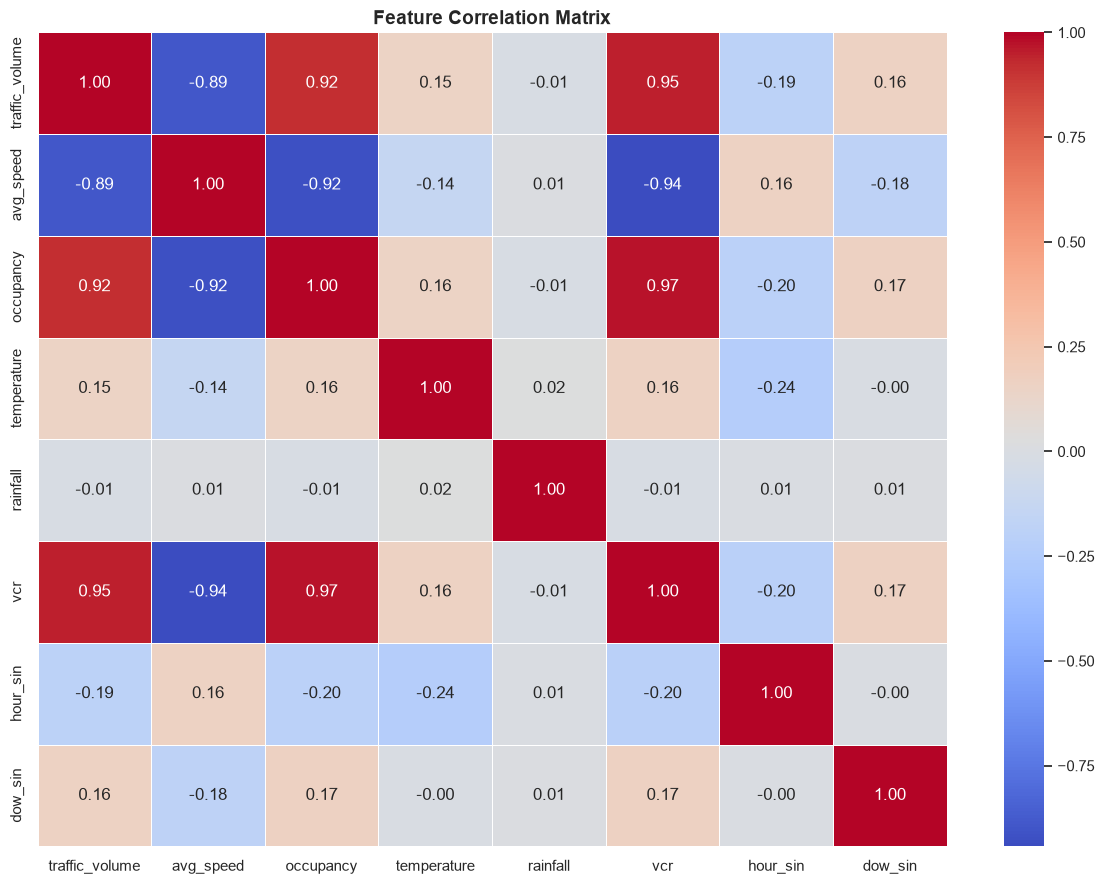

In [18]:
plt.figure(figsize=(12, 9))
numeric_cols = df.select_dtypes(include=[np.number]).columns
key_cols = [
    c
    for c in [
        "traffic_volume",
        "avg_speed",
        "occupancy",
        "temperature",
        "rainfall",
        "vcr",
        "hour_sin",
        "dow_sin",
    ]
    if c in numeric_cols
]

corr = df[key_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Matrix", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()